In [1]:
using MPOFuncs

In [2]:
using Plots
# use the miniconda Python (has matplotlib); must be set before PythonPlot is first loaded.
# (VS Code notebooks skip ~/.julia/config/startup.jl, which sets this for the REPL/scripts)
ENV["JULIA_CONDAPKG_BACKEND"] = "Null"
ENV["JULIA_PYTHONCALL_EXE"] = "/opt/miniconda3/bin/python3"
import PythonPlot as plt
plt.matplotlib.style.use("physrev.mplstyle")   # same style as the paper figures (Code/physrev.mplstyle)
# notebook images are PNGs at figure.dpi (default 100 → a 3.4" figure is only 340 px wide and looks blurry);
# saved PDFs are vector and unaffected
plt.matplotlib.rcParams["figure.dpi"] = 200;

# Emitting a Photon

In [3]:
no_cavs = 20
depha = 0.1
gamma = 1
dt = 0.01
t_final = 20.0



20.0

Dephasing vs no of cavities needed 

In [28]:
one_dc_list = [] #capture 99.9%
two_dc_list = [] # capture 99.99%

for depha in 0:0.001:0.02
    println(depha)
    funcs, e_vals = MPOFuncs.g2(gamma, depha, t_final, dt, 1)
    push!(one_dc_list, findfirst(x -> x>0.999, cumsum(e_vals)))
    push!(two_dc_list, findfirst(x -> x>0.9999, cumsum(e_vals)))
end

0.0
0.001
0.002
0.003
0.004
0.005
0.006
0.007
0.008
0.009
0.01
0.011
0.012
0.013
0.014
0.015
0.016
0.017
0.018
0.019
0.02


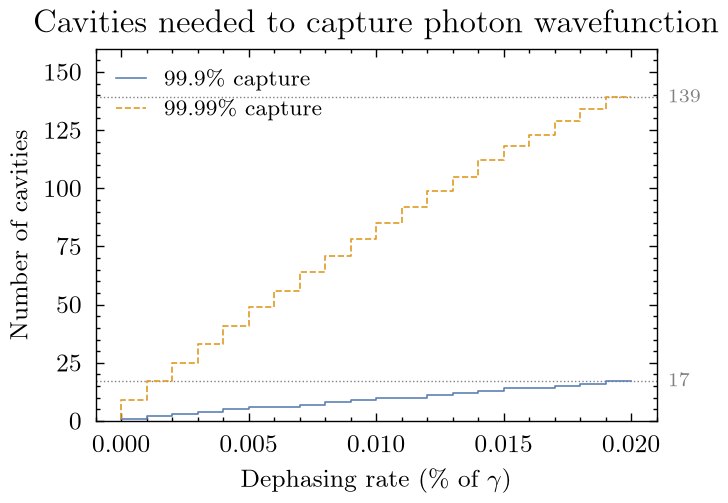

Python: (0.0, 159.85)

In [29]:
depha_list = collect(0:0.001:0.02)
fig, ax = plt.subplots(figsize=(3.4, 2.4))
# the style renders text with LaTeX, so % has to be escaped as \%
# step, not plot: the cavity count is an integer that jumps, and plot would draw sloped lines between grid points.
# where="pre" draws each grid point's count back to the previous point, so the curve never shows fewer cavities than needed
ax.step(depha_list, Int.(one_dc_list), where="pre", label=raw"99.9\% capture")
ax.step(depha_list, Int.(two_dc_list), where="pre", label=raw"99.99\% capture")
ax.set_xlabel(raw"Dephasing rate (\% of $\gamma$)")
ax.set_ylabel("Number of cavities")
ax.set_title("Cavities needed to capture photon wavefunction")
ax.legend(frameon=false)

# grey guides: cavities needed at dephasing 0.02
i_ref = findfirst(x -> isapprox(x, 0.02), depha_list)
for n in (one_dc_list[i_ref], two_dc_list[i_ref])
    ax.axhline(n, color="grey", lw=0.5, ls=":", zorder=0)
    # just outside the right edge (x in axes units, y in data units), like a right-hand tick label
    ax.text(1.02, n, "$n", color="grey", fontsize=7, va="center", ha="left", transform=ax.get_yaxis_transform())
end
ax.set_ylim(0, 1.15 * maximum(two_dc_list))   # headroom so the top line clears the frame
# fig.savefig("Ch1_cavities.pdf", bbox_inches="tight")

Avg bond dim vs dephasing

In [6]:
bonddim_list_10 = [] 
bonddim_list_4 = [] 


for depha in 0:0.001:0.02
    println(depha)
    mpo, sites, e_vals = MPOFuncs.capture_photon(4, depha, gamma, dt, t_final)
    push!(bonddim_list_4, sum(linkdims(mpo))/4)
end

0.0
[==============================] t = 20.0/20.0  dt = 0.061  χ = 4  elapsed 32s  ETA ~0s          


LoadError: UndefVarError: `linkdims` not defined

In [ ]:
plot(bonddim_list_4)

[==============================] t = 5.0/5  dt = 0.075  χ = 6  elapsed 36s  ETA ~0s            


(ITensorMPS.MPO(4), ITensors.Index{Int64}[(dim=3|id=78|"Qudit,Site,n=2"), (dim=3|id=756|"Qudit,Site,n=3"), (dim=3|id=226|"Qudit,Site,n=4"), (dim=3|id=124|"Qudit,Site,n=5")], [0.9088248226105605, 0.044528775215293345, 0.014214418629620409, 0.006853390145834068, 0.004002319375502467, 0.0026139352338146104, 0.0018373843054269327, 0.0013604849845029496, 0.0010471518161330592, 0.0008304896845158162  …  1.5223922237387316e-9, 1.5084404694098193e-9, 1.4940320294386128e-9, 1.4790620575051833e-9, 1.4633809469714443e-9, 1.4467613065815007e-9, 1.4288237168747074e-9, 1.4088310683047835e-9, 1.3848497262659583e-9, 1.2761618853901047e-9])